In [9]:
# Data Exploration

# np for mathematical and numerical operations , pands for reading and analyzing the data , Matplotlib for graphics , data visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# model_selection:  وتقسيم البيانات training and testing
from sklearn.model_selection import train_test_split

# for scaling
# StandardScaler: بيحوّل القيم بحيث يكون متوسطها تقريبًا 0 والانحراف المعياري 1.
# MinMaxScaler: بيحوّل القيم غالبًا إلى نطاق من 0 إلى 1.
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# بنا و تدريب ال Linear Regression.
from sklearn.linear_model import LinearRegression
# مدى قدرة النموذج على تفسير التغيّر في الأسعار
# 1 best , 0 not the good enogh  , 0> worst prediction
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# بيحدد شكل الرسمه و خلفيه بيضاء و , بيخلي ال pd تعرض العواميد
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [10]:
# Load the data

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

train.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [11]:
# num of rows and num ofcolumns
print("Rows   :", train.shape[0])
print("Columns:", train.shape[1])

Rows   : 19237
Columns: 18


In [12]:
#  عدد (Rows)
#  أسماء (Columns)
# Non-Null Count: عدد القيم الموجودة في كل عمود،  Missing Values.
# Datatype  بتاعت colmns
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  object 
 3   Manufacturer      19237 non-null  object 
 4   Model             19237 non-null  object 
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  object 
 7   Leather interior  19237 non-null  object 
 8   Fuel type         19237 non-null  object 
 9   Engine volume     19237 non-null  object 
 10  Mileage           19237 non-null  object 
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  object 
 13  Drive wheels      19237 non-null  object 
 14  Doors             19237 non-null  object 
 15  Wheel             19237 non-null  object 
 16  Color             19237 non-null  object

In [13]:
# statistics operations زي mean , meadian , std and round(1) دي معناها قرّب النتائج إلى رقم عشري واحد.
train.describe().round(1)

,ID,Price,Prod. year,Cylinders,Airbags
count,19237.0,19237.0,19237.0,19237.0,19237.0
mean,45576535.9,18555.9,2010.9,4.6,6.6
std,936591.4,190581.3,5.7,1.2,4.3
min,20746880.0,1.0,1939.0,1.0,0.0
25%,45698374.0,5331.0,2009.0,4.0,4.0
50%,45772308.0,13172.0,2012.0,4.0,6.0
75%,45802036.0,22075.0,2015.0,4.0,12.0
max,45816654.0,26307500.0,2020.0,16.0,16.0


In [14]:
# isna بيجيب القيم الفاضية ويعملها sum اول sum في كل عمود التانيه كلهم
# بيعمل sum لي duplicated rows
# IDs المتكرر
print("Total missing values:", train.isna().sum().sum())
print("Duplicated rows     :", train.duplicated().sum())
print("Repeated cars IDs:", train["ID"].duplicated().sum())

Total missing values: 0
Duplicated rows     : 313
Repeated cars IDs: 313


In [15]:
repeated = train[train["ID"].duplicated(keep=False)].sort_values("ID")
repeated[["ID", "Price", "Manufacturer", "Model"]].head(6)

,ID,Price,Manufacturer,Model
7269,35464629,7840,HONDA,FIT
5754,35464629,7840,HONDA,FIT
1107,36559154,19726,MERCEDES-BENZ,Sprinter 411
6732,36559154,19726,MERCEDES-BENZ,Sprinter 411
9990,41770767,11917,NISSAN,Murano
13822,41770767,11917,NISSAN,Murano


In [16]:
# Count unique car IDs
# بيحسب عدد  IDs المختلفة
# بيحسب إجمالي الصفوف.
print("Unique IDs:", train["ID"].nunique())
print("Total rows:", len(train))

Unique IDs: 18924
Total rows: 19237


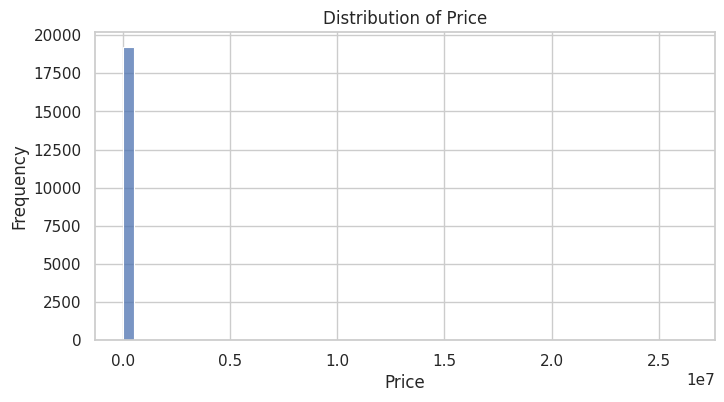

In [17]:
# Visualize the distribution of car prices
#بيحدد حجم الرسم ,    بيقسم الأسعار إلى 50 مجموعة    , بيعرض الرسم.
# الأسعار الأكثر تكرارًا في الداتا.
# بيرسم Histogram يوضح توزيع الأسعار.
plt.figure(figsize=(8, 4))
sns.histplot(train["Price"], bins=50)

plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

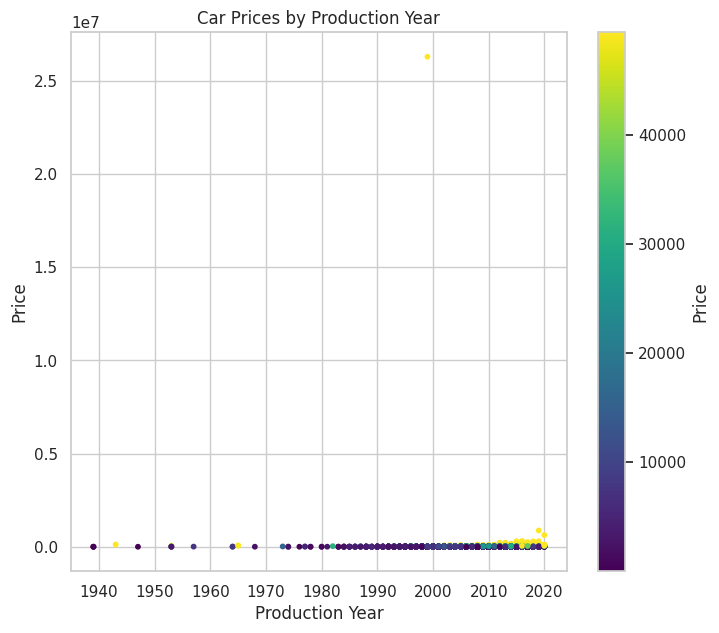

In [18]:
# Scatter plot for relationship between car year (x) and the price (y)

plt.figure(figsize=(8, 7))

plt.scatter(
    train["Prod. year"],
    train["Price"],
    c=train["Price"],
    s=10,
    cmap="viridis",
    vmax=train["Price"].quantile(0.95)
)

plt.colorbar(label="Price")
plt.xlabel("Production Year")
plt.ylabel("Price")
plt.title("Car Prices by Production Year")

plt.show()

In [19]:
# Calculate correlation between numerical features and car price
# طبيعي إن ارتباط Price مع نفسه يساوي 1.
# قريب من +1	علاقة موجبة قوية
# قريب من 0	علاقة خطية ضعيفة أو غير موجودة
# قريب من -1	علاقة سالبة قوية
correlation = (
    train.corr(numeric_only=True)["Price"]
    .drop("Price")
    .sort_values(ascending=False)
    .round(2)
    .to_frame("Correlation with Price")
)

correlation

,Correlation with Price
Prod. year,0.01
Cylinders,0.01
ID,-0.00
Airbags,-0.01


In [20]:
# Data Cleaning
# fix data types
# Remove "km" and convert Mileage to numeric for mathematical operations

train["Mileage"] = (
    train["Mileage"]
    .str.replace(" km", "", regex=False)
    .astype(float)
)
# Check the data type
print(train["Mileage"].dtype)
train["Mileage"].head()


float64


,Mileage
0,186005.0
1,192000.0
2,200000.0
3,168966.0
4,91901.0


In [21]:
# calculate Duplicate rowws and IDs
print("Duplicated rows   :", train.duplicated().sum())
print("Repeated cars IDs:", train["ID"].duplicated().sum())

Duplicated rows   : 313
Repeated cars IDs: 313


In [22]:
# Invalid values
# Check cars with zero cylinders
print("Cars with 0 cylinders:", (train["Cylinders"] == 0).sum())
# Display cars with more than 12 cylinders
train[train["Cylinders"] > 12][["ID", "Price", "Manufacturer", "Cylinders"]]

Cars with 0 cylinders: 0


,ID,Price,Manufacturer,Cylinders
456,45773579,11604,OPEL,16.0
1917,45768286,7000,HONDA,16.0
6863,45802046,21953,HYUNDAI,16.0
8358,45797531,15681,CHEVROLET,14.0
12550,45770557,39829,BMW,16.0
16487,45772894,7213,OPEL,16.0


The dataset contains no cars with zero cylinders.
However, 6 cars have more than 12 cylinders.
These values maybe outlires

In [23]:
# missing values
# Check the num of missing values in all column isna() for NaN
train.isna().sum()
# calculate missing values represented by (-) in levy colmn
print("Missing Levy values:", (train["Levy"] == "-").sum())
# Replace (-) with NaN in Levy colmn
train["Levy"] = train["Levy"].replace("-", np.nan)
# Check missing values in Levy column
print("Missing Levy values:", train["Levy"].isna().sum())

Missing Levy values: 5819
Missing Levy values: 5819


In [24]:
# outlires
# Calculate Q1 and Q3
q1 = train["Price"].quantile(0.25)
q3 = train["Price"].quantile(0.75)

# Calculate IQR
iqr = q3 - q1

# low بيحدد أقل حد مقبول حسب الطريقة
# high بيحدد أعلى حد مقبول
# أي قيمة خارج الحدود دي  Outlier
# Calculate lower and upper limits
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

# Count outliers
outliers = ((train["Price"] < low) | (train["Price"] > high)).sum()

print("Lower limit:", low)
print("Upper limit:", high)
print("Price outliers:", outliers)

Lower limit: -19785.0
Upper limit: 47191.0
Price outliers: 1073


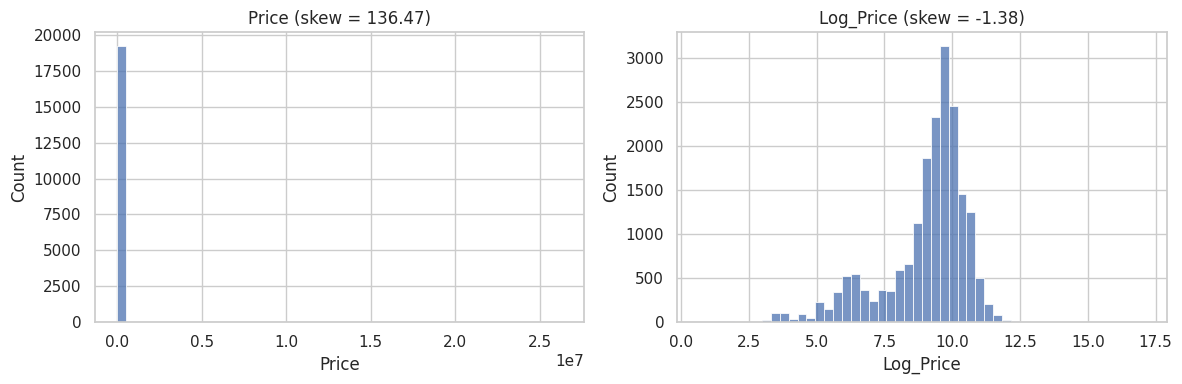

In [25]:
#.Skewed target: log transform

# Apply log transformation to Price
train["Log_Price"] = np.log1p(train["Price"])

# Create 2 histograms to compare Price distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot original Price distribution
sns.histplot(train["Price"], bins=50, ax=axes[0]).set_title(
    f"Price (skew = {train['Price'].skew():.2f})"
)

# Plot Log_Price distribution
sns.histplot(train["Log_Price"], bins=50, ax=axes[1]).set_title(
    f"Log_Price (skew = {train['Log_Price'].skew():.2f})"
)

plt.tight_layout()
plt.show()

In [26]:
# Feature Engineering, Encoding, Train/Test Split & Scaling
# Check the range of car production years
print("Oldest car year:", train["Prod. year"].min())
print("Newest car year:", train["Prod. year"].max())

# Calculate car age  using 2020 as the reference year
train["Car_Age"] = 2020 - train["Prod. year"]

# Display the original and new features
train[["Prod. year", "Car_Age"]].head()

# Calculate average mileage per year  و (Car_Age + 1)    عشان منقسمش على  0
train["Mileage_Per_Year"] = train["Mileage"] / (train["Car_Age"] + 1)

# Display the original and new features
train[["Mileage", "Car_Age", "Mileage_Per_Year"]].head()

Oldest car year: 1939
Newest car year: 2020


,Mileage,Car_Age,Mileage_Per_Year
0,186005.0,10,16909.545455
1,192000.0,9,19200.000000
2,200000.0,14,13333.333333
3,168966.0,9,16896.600000
4,91901.0,6,13128.714286


In [27]:
# Display all current column names
print("Columns:", list(train.columns))
# عملنا drop لي ال ID
train = train.drop(columns=["ID"])
print("Columns left:", list(train.columns))


Columns: ['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags', 'Log_Price', 'Car_Age', 'Mileage_Per_Year']
Columns left: ['Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags', 'Log_Price', 'Car_Age', 'Mileage_Per_Year']


In [28]:
# One-Hot Encoding to Fuel type
train = pd.get_dummies(
    train,
    columns=["Fuel type"],
    drop_first=True,
    dtype=int
)
# Display the new shape
print("New shape:", train.shape)

New shape: (19237, 25)


In [29]:
# Display the number of unique values in categorical columns
train.select_dtypes(include="object").nunique().sort_values(ascending=False)


,0
Model,1590
Levy,558
Engine volume,107
Manufacturer,65
Color,16
Category,11
Gear box type,4
Doors,3
Drive wheels,3
Leather interior,2


In [30]:
# Display the number of unique manufacturers
print("Number of manufacturers:", train["Manufacturer"].nunique())

Number of manufacturers: 65


In [31]:
# One-Hot Encoding to Manufacturer
train = pd.get_dummies(
    train,
    columns=["Manufacturer"],
    drop_first=True,
    dtype=int
)

# Display the new shape
print("New shape:", train.shape)

New shape: (19237, 88)


In [32]:
# Check Levy data type and sample values
print("Data type:", train["Levy"].dtype)
train["Levy"].head()

Data type: object


,Levy
0,1399
1,1018
2,NaN
3,862
4,446


In [33]:
# Convert Levy to numeric
train["Levy"] = pd.to_numeric(train["Levy"], errors="coerce")

# Check data type
print("Data type:", train["Levy"].dtype)

Data type: float64


In [34]:
# Replace missing Levy values with the median
train["Levy"] = train["Levy"].fillna(train["Levy"].median())

# Check missing values
print("Missing Levy values:", train["Levy"].isna().sum())

Missing Levy values: 0


In [35]:
train.select_dtypes(include="object").columns

Index(['Model', 'Category', 'Leather interior', 'Engine volume',
       'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color'],
      dtype='object')

In [36]:
print("Columns left:", list(train.columns))

Columns left: ['Price', 'Levy', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags', 'Log_Price', 'Car_Age', 'Mileage_Per_Year', 'Fuel type_Diesel', 'Fuel type_Hybrid', 'Fuel type_Hydrogen', 'Fuel type_LPG', 'Fuel type_Petrol', 'Fuel type_Plug-in Hybrid', 'Manufacturer_ALFA ROMEO', 'Manufacturer_ASTON MARTIN', 'Manufacturer_AUDI', 'Manufacturer_BENTLEY', 'Manufacturer_BMW', 'Manufacturer_BUICK', 'Manufacturer_CADILLAC', 'Manufacturer_CHEVROLET', 'Manufacturer_CHRYSLER', 'Manufacturer_CITROEN', 'Manufacturer_DAEWOO', 'Manufacturer_DAIHATSU', 'Manufacturer_DODGE', 'Manufacturer_FERRARI', 'Manufacturer_FIAT', 'Manufacturer_FORD', 'Manufacturer_GAZ', 'Manufacturer_GMC', 'Manufacturer_GREATWALL', 'Manufacturer_HAVAL', 'Manufacturer_HONDA', 'Manufacturer_HUMMER', 'Manufacturer_HYUNDAI', 'Manufacturer_INFINITI', 'Manufacturer_ISUZU', 'Manufacturer_JAGUAR', 'Manufacturer_JEEP', 'Ma

In [37]:
# Separate features and target

X = train.drop(columns=["Price", "Log_Price"])
y = train["Log_Price"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes
print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (15389, 86)
Test : (3848, 86)


In [38]:
# Remove remaining categorical columns
X_train = X_train.select_dtypes(exclude="object")
X_test = X_test.select_dtypes(exclude="object")

# Check the new shapes
print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (15389, 77)
Test : (3848, 77)


In [39]:
  # Select Mileage for scaling comparison
example = X_train[["Mileage"]]

# Compare original, StandardScaler, and MinMaxScaler
compare = pd.DataFrame({
    "original": example["Mileage"],
    "standard": StandardScaler().fit_transform(example).ravel(),
    "minmax": MinMaxScaler().fit_transform(example).ravel(),
})

# Display statistical comparison
compare.describe().round(2)

,original,standard,minmax
count,1.538900e+04,15389.00,15389.00
mean,1.578701e+06,0.00,0.00
std,4.962160e+07,1.00,0.02
min,0.000000e+00,-0.03,0.00
25%,6.991800e+04,-0.03,0.00
50%,1.254450e+05,-0.03,0.00
75%,1.888880e+05,-0.03,0.00
max,2.147484e+09,43.25,1.00


In [40]:
# Train Linear Regression using one feature
line = LinearRegression()
# تدريب بي Mileage to predict Log_Price
line.fit(X_train[["Mileage"]], y_train)
# intercept_: قيمة التقاطع مع محور Y.
# coef_: معامل الانحدار، وبيوضح تأثير تغير Mileage على التوق
print("Intercept b:", round(line.intercept_, 4))
print("Slope w    :", round(line.coef_[0], 4))

Intercept b: 9.0241
Slope w    : -0.0


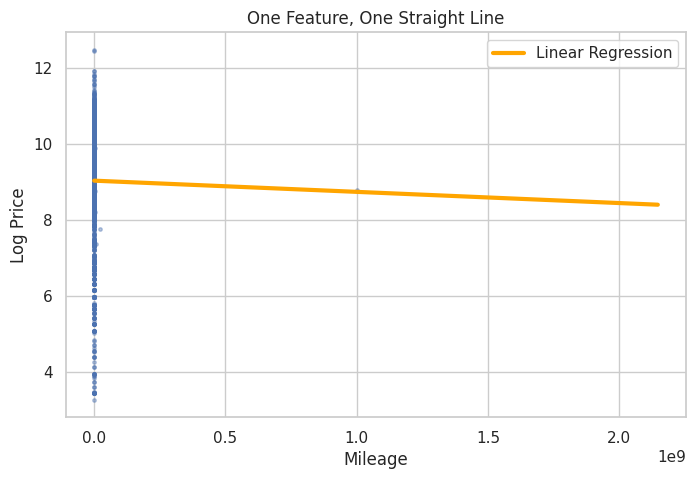

In [41]:
# Select a sample of 2000 rows
sample = X_train.sample(2000, random_state=0)

# Create values for the regression line
grid = pd.DataFrame({
    "Mileage": np.linspace(
        X_train["Mileage"].min(),
        X_train["Mileage"].max(),
        200
    )
})

# Plot the actual data points
plt.figure(figsize=(8, 5))
plt.scatter(
    sample["Mileage"],
    y_train.loc[sample.index],
    s=6,
    alpha=0.4
)

# Plot the regression line
plt.plot(
    grid["Mileage"],
    line.predict(grid),
    color="orange",
    linewidth=3,
    label="Linear Regression"
)

plt.xlabel("Mileage")
plt.ylabel("Log Price")
plt.title("One Feature, One Straight Line")
plt.legend()
plt.show()

In [42]:
# Store model results
results = []

# Calculate RMSE
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))


# Evaluate the model
def report(name, model, X_tr, y_tr, X_te, y_te, save=True):
    """Fit the model, evaluate it on train and test, and save the results."""

    model.fit(X_tr, y_tr)

    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    row = {
        "model": name,
        "train R2": r2_score(y_tr, pred_tr),
        "test R2": r2_score(y_te, pred_te),
        "test RMSE (log)": rmse(y_te, pred_te),
    }

    if save:
        results.append(row)

    return pd.DataFrame([row]).round(3)


# Evaluate Linear Regression using Mileage only
report(
    "Linear: Mileage only",
    LinearRegression(),
    X_train[["Mileage"]],
    y_train,
    X_test[["Mileage"]],
    y_test
)

,model,train R2,test R2,test RMSE (log)
0,Linear: Mileage only,0.0,0.001,1.559
